# Handwritten Digit Classification (MNIST)
**Machine Learning Project: SRM University AP, CSE**

Models compared: **Logistic Regression**, **SVM (RBF)** and **CNN**, all on the same data and split.

**How to run:** Runtime → Change runtime type → **T4 GPU** (optional, makes the CNN faster) → Runtime → Run all.
Total time is roughly 8 to 12 minutes. Every figure is saved to a `figures/` folder, and the last cell zips everything for download (use these in the PPT and report).

## 0. Setup

In [1]:
!pip install -q gradio

In [2]:
import os, time, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve, auc)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.family": "serif"})

os.makedirs("figures", exist_ok=True)
def save_fig(name):
    plt.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 1. Load the dataset
MNIST has 70,000 grayscale images of size 28×28 (60,000 train and 10,000 test) with labels 0 to 9.
*Report: Section 3.1*

In [3]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Train images:", x_train_full.shape, "| Train labels:", y_train_full.shape)
print("Test images :", x_test.shape, "| Test labels :", y_test.shape)
print("Data type   :", x_train_full.dtype, "| Pixel range:", x_train_full.min(), "to", x_train_full.max())
print("Classes     :", np.unique(y_train_full))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train images: (60000, 28, 28) | Train labels: (60000,)
Test images : (10000, 28, 28) | Test labels : (10000,)
Data type   : uint8 | Pixel range: 0 to 255
Classes     : [0 1 2 3 4 5 6 7 8 9]


## 2. Exploratory Data Analysis
*Report: Section 3.3*

,Train,Test,Train %
0,5923,980,9.87
1,6742,1135,11.24
2,5958,1032,9.93
3,6131,1010,10.22
4,5842,982,9.74
5,5421,892,9.04
6,5918,958,9.86
7,6265,1028,10.44
8,5851,974,9.75
9,5949,1009,9.92


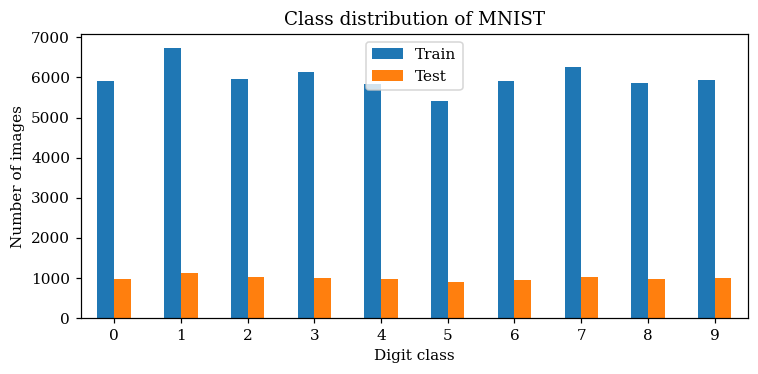

Missing values in training data: 0


In [4]:
# 2.1 Class distribution
counts = pd.DataFrame({
    "Train": pd.Series(y_train_full).value_counts().sort_index(),
    "Test":  pd.Series(y_test).value_counts().sort_index()
})
counts["Train %"] = (counts["Train"] / counts["Train"].sum() * 100).round(2)
display(counts)

fig, ax = plt.subplots(figsize=(7, 3.5))
counts[["Train", "Test"]].plot(kind="bar", ax=ax, rot=0)
ax.set_xlabel("Digit class"); ax.set_ylabel("Number of images")
ax.set_title("Class distribution of MNIST")
plt.tight_layout(); save_fig("fig_3_1_class_distribution"); plt.show()

print("Missing values in training data:", int(np.isnan(x_train_full.astype('float32')).sum()))

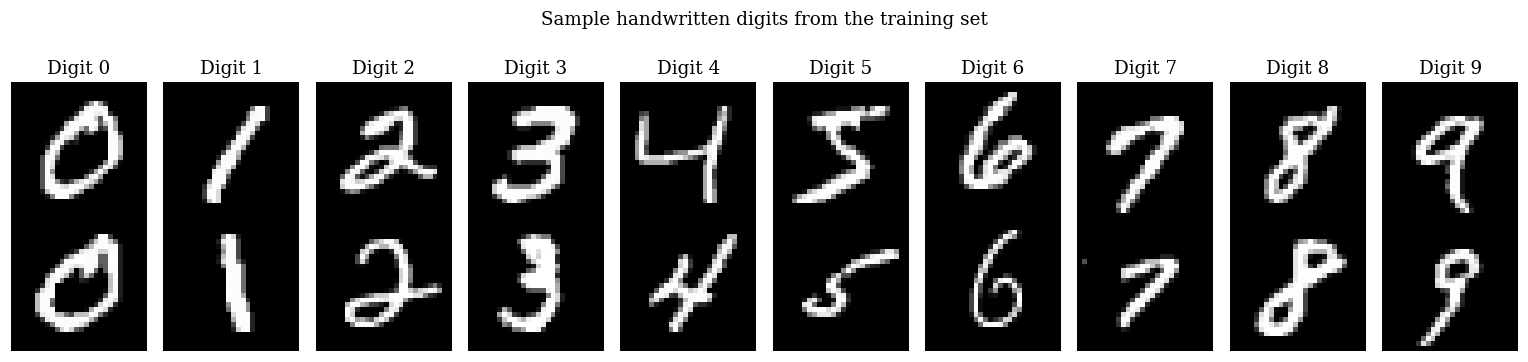

In [5]:
# 2.2 Sample images
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for d in range(10):
    idx = np.where(y_train_full == d)[0][:2]
    for r, i in enumerate(idx):
        axes[r, d].imshow(x_train_full[i], cmap="gray")
        axes[r, d].axis("off")
        if r == 0: axes[r, d].set_title(f"Digit {d}")
plt.suptitle("Sample handwritten digits from the training set", y=1.02)
plt.tight_layout(); save_fig("fig_3_2_sample_digits"); plt.show()

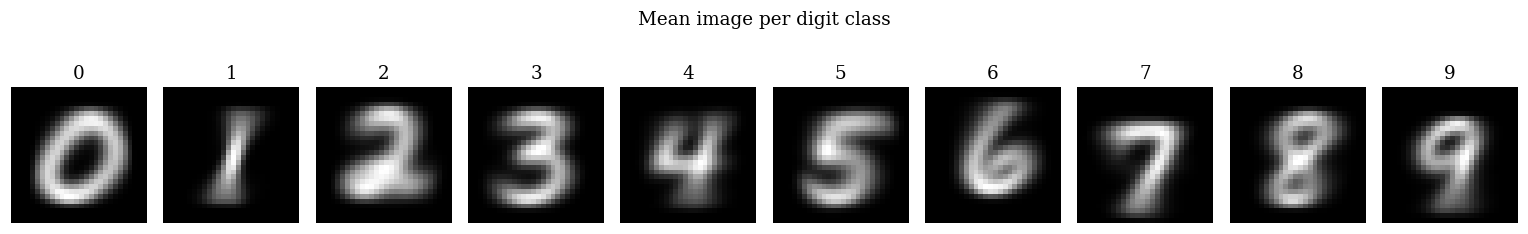

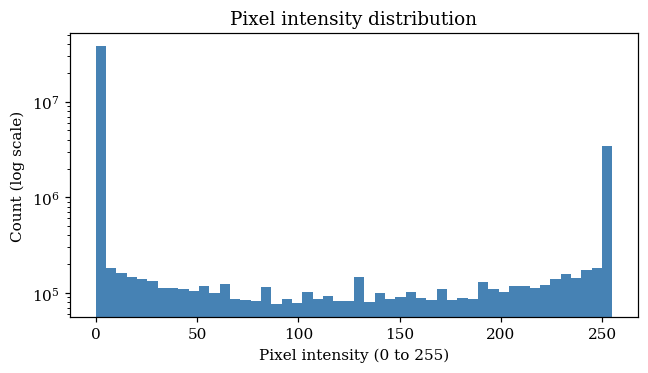

In [6]:
# 2.3 Average image of each digit and pixel intensity histogram
fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for d in range(10):
    axes[d].imshow(x_train_full[y_train_full == d].mean(axis=0), cmap="gray")
    axes[d].set_title(str(d)); axes[d].axis("off")
plt.suptitle("Mean image per digit class", y=1.08)
plt.tight_layout(); save_fig("fig_3_3_mean_digits"); plt.show()

plt.figure(figsize=(6, 3.5))
plt.hist(x_train_full.ravel(), bins=50, log=True, color="steelblue")
plt.xlabel("Pixel intensity (0 to 255)"); plt.ylabel("Count (log scale)")
plt.title("Pixel intensity distribution")
plt.tight_layout(); save_fig("fig_3_4_pixel_histogram"); plt.show()

## 3. Preprocessing and Train / Validation / Test split
- Pixels are normalized to the range 0 to 1 (same for all models).
- The original 60,000 training images are split **90% / 10%** (stratified) into **train (54,000)** and **validation (6,000)**.
- The 10,000-image MNIST test set is kept untouched until the final evaluation.
- Classical models (Logistic Regression and SVM) need flat vectors, so the 784 pixels are reduced to 100 features with **PCA**. PCA is fit on the training set only, and the CNN uses the full 28×28 images.

*Report: Sections 3.4 and 3.5*

In [7]:
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.10, stratify=y_train_full, random_state=SEED)

print(pd.DataFrame({"Split": ["Train", "Validation", "Test"],
                    "Images": [len(x_train), len(x_val), len(x_test)]}).to_string(index=False))

# Flattened + PCA features for classical models
N_PCA = 100
flat = lambda a: a.reshape(len(a), -1)
pca = PCA(n_components=N_PCA, random_state=SEED).fit(flat(x_train))
Xtr, Xva, Xte = pca.transform(flat(x_train)), pca.transform(flat(x_val)), pca.transform(flat(x_test))
print(f"PCA: 784 -> {N_PCA} features, variance retained = {pca.explained_variance_ratio_.sum()*100:.1f}%")

     Split  Images
     Train   54000
Validation    6000
      Test   10000
PCA: 784 -> 100 features, variance retained = 91.5%


## 4. Evaluation helper
Computes Accuracy, Precision, Recall, F1 (macro-averaged over the 10 classes) and ROC-AUC (one-vs-rest, macro).

In [8]:
def evaluate(name, y_true, y_pred, scores):
    Y = label_binarize(y_true, classes=list(range(10)))
    auc_macro = np.mean([roc_auc_score(Y[:, i], scores[:, i]) for i in range(10)])
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="macro"),
        "Recall": recall_score(y_true, y_pred, average="macro"),
        "F1-score": f1_score(y_true, y_pred, average="macro"),
        "ROC-AUC": auc_macro,
    }

results, val_acc, train_time, preds, scores_all = [], {}, {}, {}, {}

## 5. Model 1: Logistic Regression
Hyperparameter tuning on the validation set (parameter `C`). *Report: Sections 4.2 to 4.4*

In [9]:
lr_tune = []
for C in [0.01, 0.1, 1, 10]:
    m = LogisticRegression(C=C, max_iter=1000).fit(Xtr, y_train)
    lr_tune.append({"C": C, "Validation accuracy": m.score(Xva, y_val)})
lr_tune = pd.DataFrame(lr_tune); display(lr_tune)
best_C = lr_tune.loc[lr_tune["Validation accuracy"].idxmax(), "C"]
print("Best C:", best_C)

t0 = time.time()
lr = LogisticRegression(C=best_C, max_iter=1000).fit(Xtr, y_train)
train_time["Logistic Regression"] = time.time() - t0

name = "Logistic Regression"
preds[name] = lr.predict(Xte); scores_all[name] = lr.predict_proba(Xte)
val_acc[name] = lr.score(Xva, y_val)
results.append(evaluate(name, y_test, preds[name], scores_all[name]))
print(f"Validation acc: {val_acc[name]:.4f} | Test acc: {results[-1]['Accuracy']:.4f} | Train time: {train_time[name]:.1f}s")

,C,Validation accuracy
0,0.01,0.912167
1,0.10,0.917333
2,1.00,0.917500
3,10.00,0.917500


Best C: 1.0
Validation acc: 0.9175 | Test acc: 0.9212 | Train time: 8.7s


## 6. Model 2: SVM (RBF kernel)
Tuned quickly on a 10,000-image subset of the training data (to save time), then retrained on the full training set with the best `C`.

In [10]:
rng = np.random.RandomState(SEED)
sub = rng.choice(len(Xtr), 10000, replace=False)
svm_tune = []
for C in [1, 5, 10]:
    m = SVC(kernel="rbf", C=C, gamma="scale").fit(Xtr[sub], y_train[sub])
    svm_tune.append({"C": C, "Validation accuracy": m.score(Xva, y_val)})
svm_tune = pd.DataFrame(svm_tune); display(svm_tune)
best_C_svm = svm_tune.loc[svm_tune["Validation accuracy"].idxmax(), "C"]
print("Best C:", best_C_svm)

,C,Validation accuracy
0,1,0.968500
1,5,0.974333
2,10,0.973667


Best C: 5


In [11]:
t0 = time.time()
svm = SVC(kernel="rbf", C=best_C_svm, gamma="scale").fit(Xtr, y_train)
train_time["SVM (RBF)"] = time.time() - t0

name = "SVM (RBF)"
preds[name] = svm.predict(Xte); scores_all[name] = svm.decision_function(Xte)
val_acc[name] = svm.score(Xva, y_val)
results.append(evaluate(name, y_test, preds[name], scores_all[name]))
print(f"Validation acc: {val_acc[name]:.4f} | Test acc: {results[-1]['Accuracy']:.4f} | Train time: {train_time[name]:.1f}s")

Validation acc: 0.9858 | Test acc: 0.9850 | Train time: 27.0s


## 7. Model 3: Convolutional Neural Network (CNN)
Two convolution blocks (Conv, Conv, MaxPool, Dropout), then a dense classifier. Training uses early stopping on validation loss.

In [12]:
xtr_c, xva_c, xte_c = x_train[..., None], x_val[..., None], x_test[..., None]

cnn = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),
    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(10, activation="softmax"),
])
cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 467,818 (1.78 MB)

 Trainable params: 467,818 (1.78 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
t0 = time.time()
history = cnn.fit(xtr_c, y_train, validation_data=(xva_c, y_val),
                  epochs=20, batch_size=128, callbacks=[early], verbose=2)
train_time["CNN"] = time.time() - t0

name = "CNN"
probs = cnn.predict(xte_c, verbose=0)
preds[name] = probs.argmax(axis=1); scores_all[name] = probs
val_acc[name] = cnn.evaluate(xva_c, y_val, verbose=0)[1]
results.append(evaluate(name, y_test, preds[name], scores_all[name]))
print(f"Validation acc: {val_acc[name]:.4f} | Test acc: {results[-1]['Accuracy']:.4f} | Train time: {train_time[name]:.1f}s")

Epoch 1/20
422/422 - 36s - 85ms/step - accuracy: 0.9167 - loss: 0.2620 - val_accuracy: 0.9825 - val_loss: 0.0647
Epoch 2/20
422/422 - 4s - 9ms/step - accuracy: 0.9762 - loss: 0.0785 - val_accuracy: 0.9848 - val_loss: 0.0572
Epoch 3/20
422/422 - 4s - 9ms/step - accuracy: 0.9822 - loss: 0.0591 - val_accuracy: 0.9893 - val_loss: 0.0417
Epoch 4/20
422/422 - 4s - 8ms/step - accuracy: 0.9858 - loss: 0.0453 - val_accuracy: 0.9897 - val_loss: 0.0379
Epoch 5/20
422/422 - 3s - 8ms/step - accuracy: 0.9881 - loss: 0.0395 - val_accuracy: 0.9888 - val_loss: 0.0379
Epoch 6/20
422/422 - 4s - 9ms/step - accuracy: 0.9890 - loss: 0.0348 - val_accuracy: 0.9908 - val_loss: 0.0334
Epoch 7/20
422/422 - 4s - 9ms/step - accuracy: 0.9895 - loss: 0.0318 - val_accuracy: 0.9903 - val_loss: 0.0379
Epoch 8/20
422/422 - 3s - 8ms/step - accuracy: 0.9909 - loss: 0.0268 - val_accuracy: 0.9913 - val_loss: 0.0322
Epoch 9/20
422/422 - 4s - 8ms/step - accuracy: 0.9925 - loss: 0.0244 - val_accuracy: 0.9913 - val_loss: 0.0296

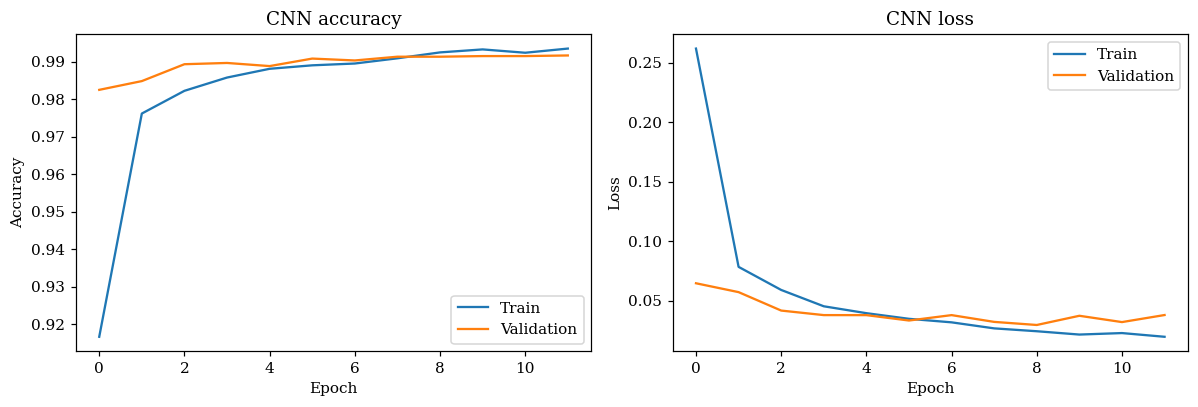

In [14]:
# Training vs validation curves (report Section 6.5)
h = history.history
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(h["accuracy"], label="Train"); ax[0].plot(h["val_accuracy"], label="Validation")
ax[0].set_title("CNN accuracy"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy"); ax[0].legend()
ax[1].plot(h["loss"], label="Train"); ax[1].plot(h["val_loss"], label="Validation")
ax[1].set_title("CNN loss"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss"); ax[1].legend()
plt.tight_layout(); save_fig("fig_6_1_cnn_training_curves"); plt.show()

## 8. Results on the unseen test set
*Report: Sections 6.1 and 6.2*

,Val Accuracy,Accuracy,Precision,Recall,F1-score,ROC-AUC,Train time (s)
Model,,,,,,,
Logistic Regression,0.9175,0.9212,0.9201,0.9201,0.9200,0.9936,8.7
SVM (RBF),0.9858,0.9850,0.9849,0.9849,0.9849,0.9983,27.0
CNN,0.9913,0.9949,0.9948,0.9948,0.9948,1.0000,75.8


Best model on test set: CNN


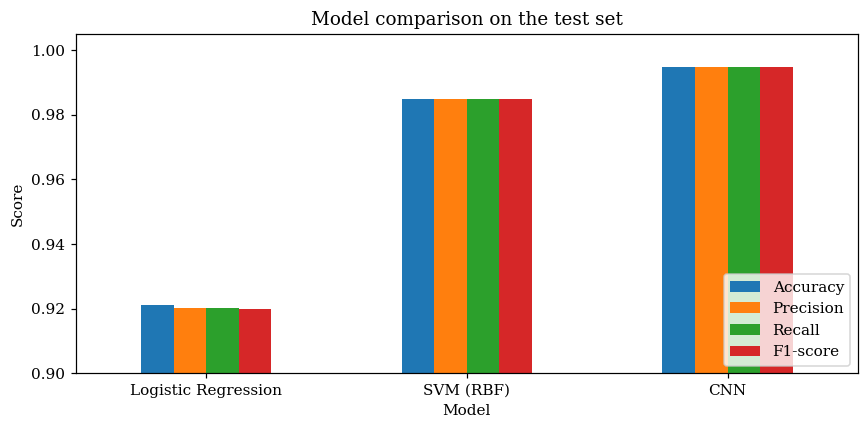

In [15]:
res = pd.DataFrame(results).set_index("Model")
res.insert(0, "Val Accuracy", pd.Series(val_acc))
res["Train time (s)"] = pd.Series(train_time).round(1)
res_display = res.copy()
for c in ["Val Accuracy", "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]:
    res_display[c] = res_display[c].round(4)
display(res_display)
res_display.to_csv("figures/model_comparison.csv")

best_model = res["Accuracy"].idxmax()
print("Best model on test set:", best_model)

ax = res[["Accuracy", "Precision", "Recall", "F1-score"]].plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_ylim(0.90, 1.005); ax.set_ylabel("Score"); ax.set_title("Model comparison on the test set")
ax.legend(loc="lower right")
plt.tight_layout(); save_fig("fig_6_2_model_comparison"); plt.show()

## 9. Confusion matrices and class-wise metrics
*Report: Sections 6.4 and 6.5*

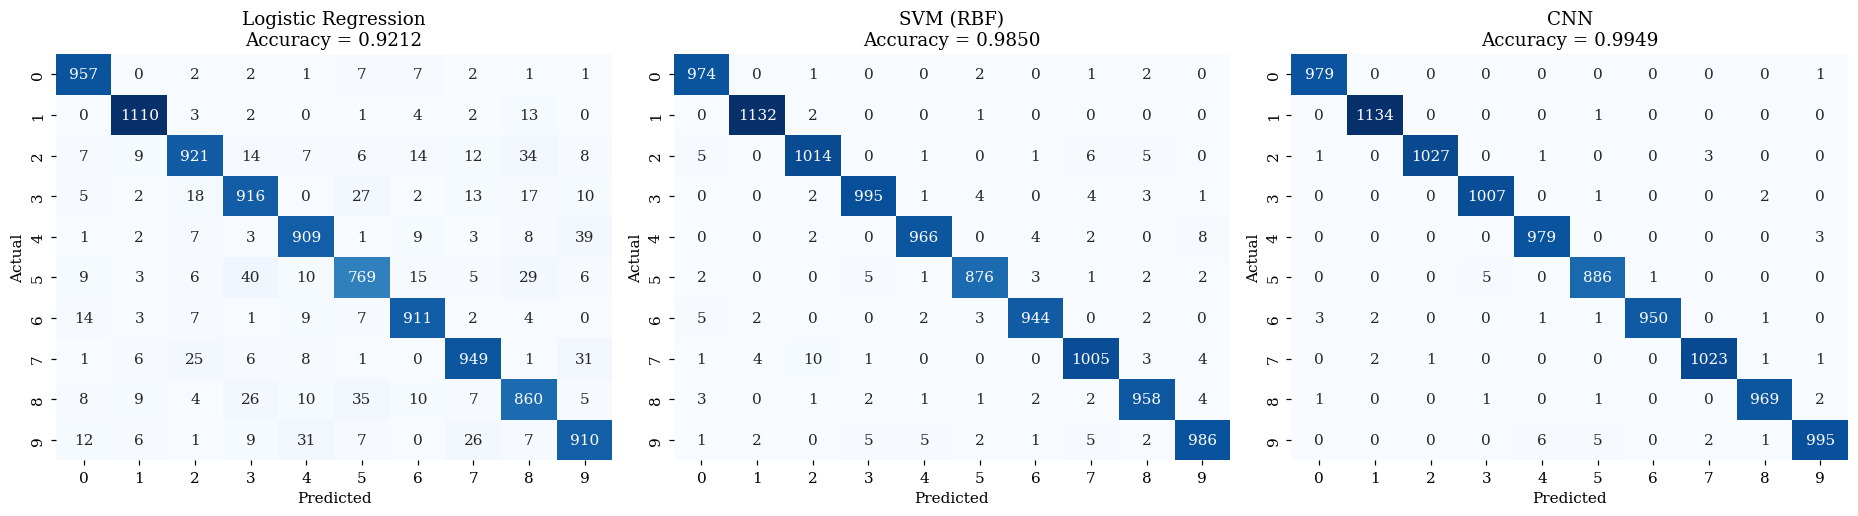

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, name in zip(axes, preds):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{name}\nAccuracy = {accuracy_score(y_test, preds[name]):.4f}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); save_fig("fig_6_3_confusion_matrices"); plt.show()

In [17]:
print(f"Class-wise metrics for the best model: {best_model}\n")
print(classification_report(y_test, preds[best_model], digits=4))

# Most frequent confusions for the best model
cm = confusion_matrix(y_test, preds[best_model]); np.fill_diagonal(cm, 0)
pairs = [(int(i), int(j), int(cm[i, j])) for i in range(10) for j in range(10) if cm[i, j] > 0]
pairs = sorted(pairs, key=lambda t: -t[2])[:5]
print("Top confusions (actual -> predicted : count):")
for a, p, n in pairs: print(f"  {a} -> {p} : {n}")

Class-wise metrics for the best model: CNN

              precision    recall  f1-score   support

           0     0.9949    0.9990    0.9969       980
           1     0.9965    0.9991    0.9978      1135
           2     0.9990    0.9952    0.9971      1032
           3     0.9941    0.9970    0.9956      1010
           4     0.9919    0.9969    0.9944       982
           5     0.9899    0.9933    0.9916       892
           6     0.9989    0.9916    0.9953       958
           7     0.9951    0.9951    0.9951      1028
           8     0.9949    0.9949    0.9949       974
           9     0.9930    0.9861    0.9896      1009

    accuracy                         0.9949     10000
   macro avg     0.9948    0.9948    0.9948     10000
weighted avg     0.9949    0.9949    0.9949     10000

Top confusions (actual -> predicted : count):
  9 -> 4 : 6
  5 -> 3 : 5
  9 -> 5 : 5
  2 -> 7 : 3
  4 -> 9 : 3


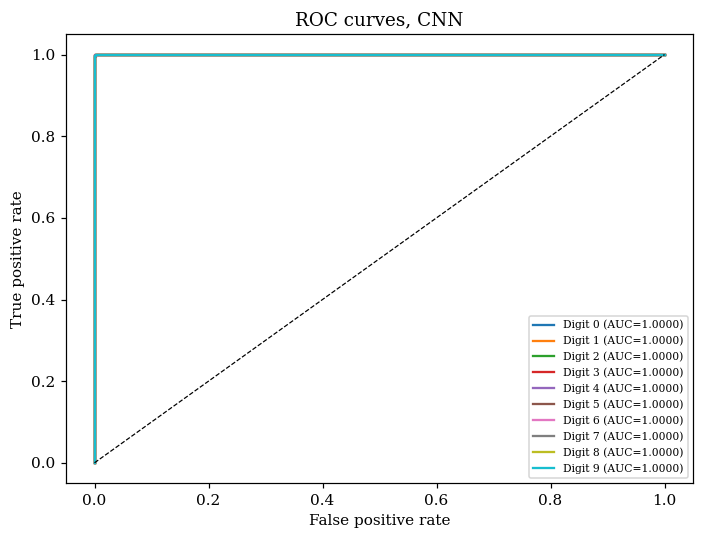

In [18]:
# ROC curves (one-vs-rest) for the best model
Y = label_binarize(y_test, classes=list(range(10)))
sc = scores_all[best_model]
plt.figure(figsize=(6.5, 5))
for i in range(10):
    fpr, tpr, _ = roc_curve(Y[:, i], sc[:, i])
    plt.plot(fpr, tpr, label=f"Digit {i} (AUC={auc(fpr, tpr):.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title(f"ROC curves, {best_model}"); plt.legend(fontsize=7, loc="lower right")
plt.tight_layout(); save_fig("fig_6_4_roc_curves"); plt.show()

## 10. Misclassified examples (error analysis)

CNN misclassified 51 of 10000 test images


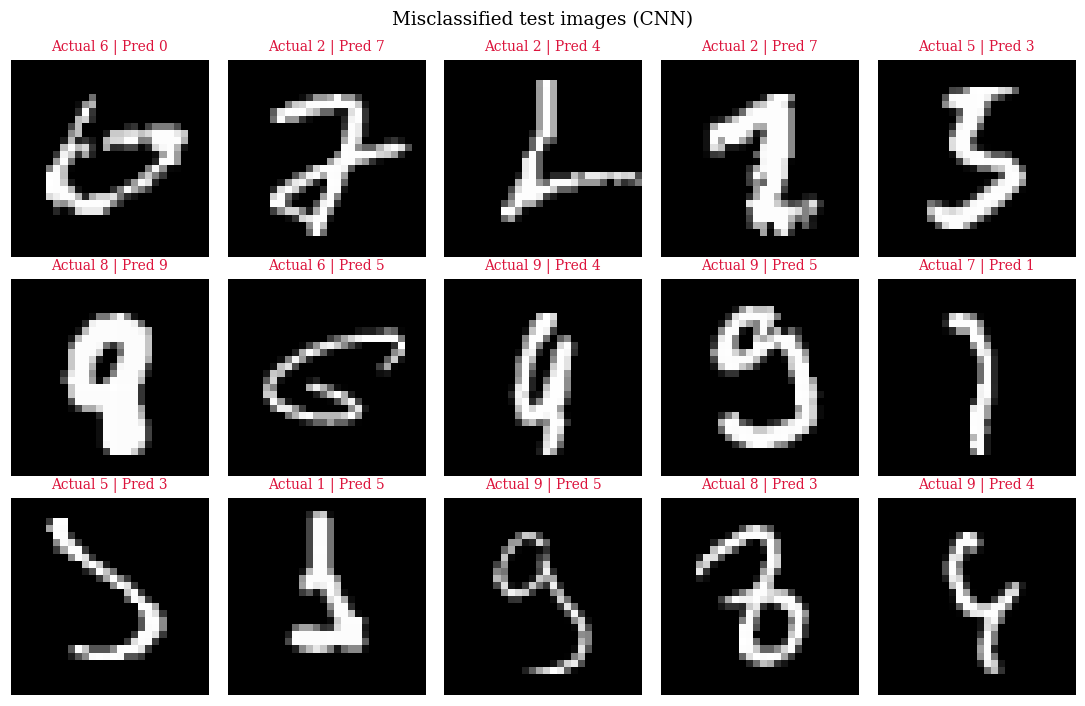

In [19]:
wrong = np.where(preds[best_model] != y_test)[0]
print(f"{best_model} misclassified {len(wrong)} of {len(y_test)} test images")
show = wrong[:15]
fig, axes = plt.subplots(3, 5, figsize=(10, 6.5))
for ax, i in zip(axes.ravel(), show):
    ax.imshow(x_test[i], cmap="gray"); ax.axis("off")
    ax.set_title(f"Actual {y_test[i]} | Pred {preds[best_model][i]}", color="crimson", fontsize=9)
plt.suptitle(f"Misclassified test images ({best_model})")
plt.tight_layout(); save_fig("fig_6_5_misclassified"); plt.show()

## 11. Sample predictions
*Report: Section 6.7*

,Record ID,Actual,Logistic Regression,SVM (RBF),CNN,Correct? (CNN)
0,9953,6,6,6,6,Yes
1,3850,9,9,9,9,Yes
2,4962,2,2,2,2,Yes
3,3886,6,6,6,6,Yes
4,5437,7,7,7,7,Yes
5,8517,6,6,6,6,Yes
6,2041,1,1,1,1,Yes
7,1989,4,4,4,4,Yes
8,1933,7,7,7,7,Yes
9,9984,1,1,1,1,Yes


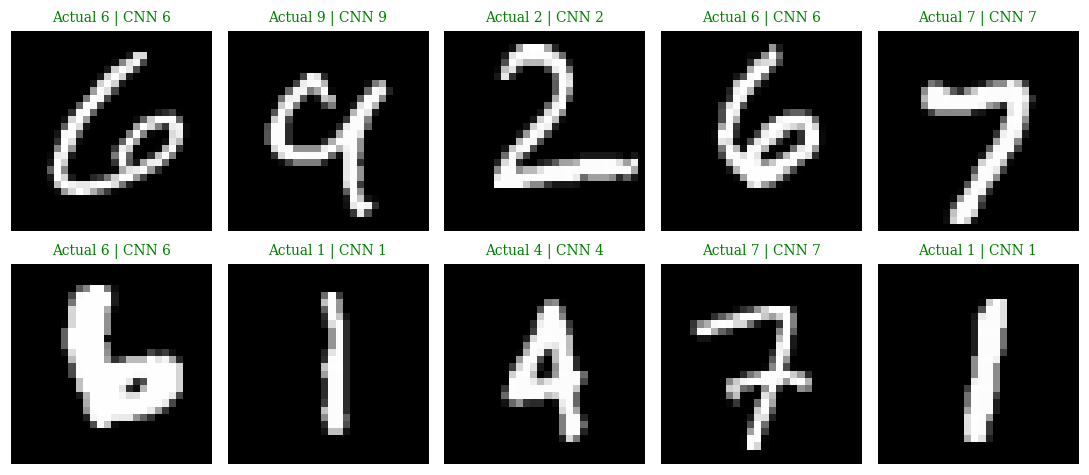

In [20]:
idx = np.random.RandomState(1).choice(len(x_test), 10, replace=False)
sample = pd.DataFrame({
    "Record ID": idx,
    "Actual": y_test[idx],
    "Logistic Regression": preds["Logistic Regression"][idx],
    "SVM (RBF)": preds["SVM (RBF)"][idx],
    "CNN": preds["CNN"][idx],
})
sample["Correct? (CNN)"] = np.where(sample["Actual"] == sample["CNN"], "Yes", "No")
display(sample)
sample.to_csv("figures/sample_predictions.csv", index=False)

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(x_test[i], cmap="gray"); ax.axis("off")
    ok = preds["CNN"][i] == y_test[i]
    ax.set_title(f"Actual {y_test[i]} | CNN {preds['CNN'][i]}", color="green" if ok else "crimson", fontsize=9)
plt.tight_layout(); save_fig("fig_6_6_sample_predictions"); plt.show()

## 12. Save the trained CNN

In [21]:
cnn.save("mnist_cnn.keras")
print("Saved mnist_cnn.keras")

Saved mnist_cnn.keras


## 13. Interactive demo: upload or draw a digit (optional)
*Report: Section 5.4. Take screenshots of this for the report and PPT.*

MNIST digits are **white on a black background**, centered and about 20×20 pixels inside a 28×28 frame. Photos and drawings are usually dark ink on white paper, so the function below converts to grayscale, inverts if needed, crops to the digit, resizes and centers it before prediction. Without this step accuracy on your own images drops a lot.

In [22]:
from PIL import Image
from scipy import ndimage

def preprocess_digit(img):
    """Convert an uploaded / drawn image into an MNIST-style 28x28 array in [0,1]."""
    if img is None:
        return None
    if isinstance(img, dict):                       # Sketchpad / ImageEditor output
        img = img.get("composite")
        if img is None:
            return None
    arr = np.array(img).astype("float32")
    if arr.ndim == 3:
        if arr.shape[2] == 4:                       # RGBA -> composite on white
            a = arr[..., 3:4] / 255.0
            arr = arr[..., :3] * a + 255.0 * (1 - a)
        arr = arr[..., :3].mean(axis=2)
    border = np.concatenate([arr[0], arr[-1], arr[:, 0], arr[:, -1]])
    if np.median(border) > 127:                     # light background -> invert
        arr = 255.0 - arr
    arr = (arr - arr.min()) / (arr.max() - arr.min() + 1e-8)
    mask = arr > 0.2
    if not mask.any():
        return None
    r = np.where(mask.any(axis=1))[0]; c = np.where(mask.any(axis=0))[0]
    digit = arr[r[0]:r[-1] + 1, c[0]:c[-1] + 1]
    h, w = digit.shape
    s = 20.0 / max(h, w)
    nh, nw = max(1, int(round(h * s))), max(1, int(round(w * s)))
    digit = np.array(Image.fromarray((digit * 255).astype("uint8")).resize((nw, nh), Image.LANCZOS)) / 255.0
    canvas = np.zeros((28, 28), dtype="float32")
    top, left = (28 - nh) // 2, (28 - nw) // 2
    canvas[top:top + nh, left:left + nw] = digit
    cy, cx = ndimage.center_of_mass(canvas)         # shift centre of mass to the middle
    canvas = ndimage.shift(canvas, (14 - cy, 14 - cx), order=1)
    return np.clip(canvas, 0, 1).astype("float32")

def predict_digit(img):
    x = preprocess_digit(img)
    if x is None:
        return {}, None
    p = cnn.predict(x[None, ..., None], verbose=0)[0]
    view = np.kron((x * 255).astype("uint8"), np.ones((5, 5), dtype="uint8"))
    return {str(i): float(p[i]) for i in range(10)}, view

In [23]:
import gradio as gr

upload_ui = gr.Interface(
    fn=predict_digit,
    inputs=gr.Image(type="numpy", sources=["upload"], label="Upload a photo or image of a digit"),
    outputs=[gr.Label(num_top_classes=3, label="Prediction"), gr.Image(label="What the model sees (28x28)")],
)
draw_input = gr.Sketchpad(label="Draw a digit") if hasattr(gr, "Sketchpad") else gr.ImageEditor(label="Draw a digit")
draw_ui = gr.Interface(
    fn=predict_digit,
    inputs=draw_input,
    outputs=[gr.Label(num_top_classes=3, label="Prediction"), gr.Image(label="What the model sees (28x28)")],
)
demo = gr.TabbedInterface([upload_ui, draw_ui], ["Upload", "Draw"], title="Handwritten Digit Classifier (CNN)")
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d9001bfd458a46d67e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 14. Download all figures and tables
Zips the `figures/` folder (all plots, the comparison table and the sample predictions) together with the trained model.

In [24]:
with zipfile.ZipFile("project_outputs.zip", "w") as z:
    for f in sorted(os.listdir("figures")):
        z.write(os.path.join("figures", f))
    z.write("mnist_cnn.keras")
try:
    from google.colab import files
    files.download("project_outputs.zip")
except ImportError:
    print("Not running in Colab. The file project_outputs.zip is in the current folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>